<center><h1>Ngo_Jesse_HW4</h1></center>
<br>
<br>

Name: Jesse Ngo
<br>
Github Username: hjngo
<br>
USC ID: 4722249405

In [1]:
# Imports

import re
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

import sklearn
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from threadpoolctl import threadpool_limits
from sklearn.feature_selection import RFE
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score, auc, log_loss)
from sklearn.exceptions import ConvergenceWarning

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# Unpenalized logistic regression on (nearly) separable data never converges: the
# coefficients keep growing. Following footnote 5, max_iter stops it early, so the
# resulting ConvergenceWarnings are expected and silenced here.
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", message=".*least populated class.*")

print("scikit-learn", sklearn.__version__, "| statsmodels", sm.__version__)

scikit-learn 1.9.0 | statsmodels 0.14.6


**Data Cleaning** (same as HW3)

A few files needed minor cleaning, which was done directly in the data files in `../data/AReM`:

| File | Problem | Fix (in the file) |
|---|---|---|
| bending2/dataset4.csv | values were separated by spaces instead of commas | replaced the spaces with commas |
| cycling/dataset9.csv, cycling/dataset14.csv | the last row had a trailing comma (an empty 8th field) | removed the trailing comma |
| sitting/dataset8.csv | only 479 rows | left as is |

In [2]:
# Question 1a (from HW3)

# Make sure path exists
dataPath = Path("..") / "data" / "AReM"
if not dataPath.exists():
    raise FileNotFoundError(f"Couldn't find {dataPath.resolve()}. The current working directory is {Path.cwd()} "
                            "-- it should be the folder this notebook is in.")

SERIES = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]
COLUMNS = ["time"] + SERIES

def dataset_number(path):
    return int(re.search(r"\d+", path.stem).group())

instances = []   # one entry per file: activity, dataset number, DataFrame

for folder in sorted(p for p in dataPath.iterdir() if p.is_dir()):
    for file in sorted(folder.glob("dataset*.csv"), key=dataset_number):
        df = pd.read_csv(file, skiprows=5, header=None, names=COLUMNS)
        instances.append({"activity": folder.name,
                          "dataset": dataset_number(file),
                          "data": df})

print(f"Instances loaded: {len(instances)}")

Instances loaded: 88


**Train/test split (1b):** datasets 1 and 2 in `bending1` and `bending2`, and datasets 1, 2 and 3 in every other folder, are the test set. This gives **69 training** and **19 test** instances.

In [3]:
# Question 1b (from HW3)

# Check's if activity is bending1 and bending2, only return true if datasets 1,2.
# If any other activity, then return true if datasets 1,2,3.
# Everything else returns false
def is_test(activity, dataset):
    if activity in ("bending1", "bending2"):
        return dataset in (1, 2)
    return dataset in (1, 2, 3)

# Set instances to be test/train
for inst in instances:
    inst["set"] = "test" if is_test(inst["activity"], inst["dataset"]) else "train"

# Verification Count
split = (pd.DataFrame([(i["activity"], i["set"]) for i in instances], columns=["activity", "set"])
           .value_counts().unstack(fill_value=0)[["train", "test"]])
split.loc["Total"] = split.sum()
split

set,train,test
activity,,
bending1,5,2
bending2,4,2
cycling,12,3
lying,12,3
sitting,12,3
standing,12,3
walking,12,3
Total,69,19


**Features (1c iv):** in HW3 I selected **mean, standard deviation and maximum** as the three most important time-domain features. Those are the features used for all of Part 2.

For a given $l$, every one of the 6 time series is broken into $l$ (approximately) equal parts with `np.array_split`, and the 3 features are computed on each part. So every instance has $6 \times 3 \times l = 18l$ features, but the number of instances stays 88. Column `mean1_2` is the mean of part 2 of time series 1. Feature sets for all $l = 1, \dots, 20$ are built once and reused.

In [4]:
# Question 1cii / 1civ (from HW3), generalized to break every series into l parts

STATS = {
    "min":       np.min,
    "max":       np.max,
    "mean":      np.mean,
    "median":    np.median,
    "std":       lambda x: np.std(x, ddof=1),
    "1st_quart": lambda x: np.percentile(x, 25),
    "3rd_quart": lambda x: np.percentile(x, 75),
}
SELECTED = ["mean", "std", "max"]          # features chosen in 1(c)iv

def extract_features(inst, l=1, stats=SELECTED):
    """Features of one instance after breaking each of its 6 series into l (approximately)
    equal parts. Column names: mean1 for l = 1, mean1_2 = mean of part 2 of series 1 for l > 1."""
    row = {}
    for i, series in enumerate(SERIES, start=1):
        x = inst["data"][series].to_numpy()
        for part, seg in enumerate(np.array_split(x, l), start=1):
            for name in stats:
                col = f"{name}{i}" if l == 1 else f"{name}{i}_{part}"
                row[col] = STATS[name](seg)
    return row

def build_features(l=1, stats=SELECTED):
    df = pd.DataFrame([extract_features(i, l, stats) for i in instances])
    df.insert(0, "activity", [i["activity"] for i in instances])
    df.insert(1, "dataset", [i["dataset"] for i in instances])
    df.insert(2, "set", [i["set"] for i in instances])
    df.index = pd.RangeIndex(1, len(df) + 1, name="Instance")
    return df

META = ["activity", "dataset", "set"]
L_VALUES = range(1, 21)
featSets = {l: build_features(l) for l in L_VALUES}     # every l used in this homework

def get_xy(l, which, binary=True):
    """Feature matrix and labels for the train or test set, for a given l."""
    df = featSets[l][featSets[l]["set"] == which]
    X = df.drop(columns=META)
    if binary:
        y = df["activity"].isin(["bending1", "bending2"]).astype(int).to_numpy()   # 1 = bending
    else:
        y = df["activity"].to_numpy()
    return X, y

featSets[1].round(2).head()

,activity,dataset,set,mean1,std1,max1,mean2,std2,max2,mean3,std3,max3,mean4,std4,max4,mean5,std5,max5,mean6,std6,max6
Instance,,,,,,,,,,,,,,,,,,,,,
1,bending1,1,test,40.62,1.48,45.00,0.36,0.32,1.30,19.04,4.46,29.50,0.83,0.97,7.23,34.31,2.19,38.25,0.57,0.58,1.92
2,bending1,2,test,42.81,1.44,45.67,0.37,0.29,1.22,20.10,3.89,29.50,0.88,1.05,5.76,33.02,2.00,38.50,0.57,0.60,3.11
3,bending1,3,train,43.95,1.56,47.40,0.43,0.34,1.70,22.12,3.03,29.75,0.50,0.55,4.44,35.59,2.00,38.50,0.49,0.51,1.79
4,bending1,4,train,42.18,3.67,47.75,0.70,0.63,3.00,22.18,3.81,30.00,0.99,0.95,5.15,33.49,3.85,38.67,0.61,0.52,2.18
5,bending1,5,train,41.68,2.24,45.75,0.54,0.41,2.83,19.01,4.09,28.25,0.84,0.93,6.42,29.86,2.41,37.50,0.38,0.39,1.79


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Scatter plots of the selected features from time series 1, 2 and 6 (bending vs. other)

In [5]:
# Helper: scatter-plot matrix colored by bending vs. other

def scatter_grid(X, y, title):
    cols = list(X.columns)
    k = len(cols)
    fig, axes = plt.subplots(k, k, figsize=(1.9 * k, 1.9 * k))
    groups = [(y == 0, "tab:blue", "other"), (y == 1, "tab:orange", "bending")]
    for r, cy in enumerate(cols):
        for c, cx in enumerate(cols):
            ax = axes[r, c]
            if r == c:
                for mask, color, name in groups:
                    ax.hist(X.loc[mask, cx], bins=12, color=color, alpha=0.6)
            else:
                for mask, color, name in groups:
                    ax.scatter(X.loc[mask, cx], X.loc[mask, cy], s=10, color=color, alpha=0.7, label=name)
            ax.set_xticks([]); ax.set_yticks([])
            if r == k - 1: ax.set_xlabel(cx, fontsize=9)
            if c == 0:     ax.set_ylabel(cy, fontsize=9)
    handles, labels = axes[0, 1].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper right", fontsize=12, markerscale=2)
    fig.suptitle(title, fontsize=14, y=1.0)
    plt.tight_layout()
    plt.show()

Training set: 9 bending, 60 other


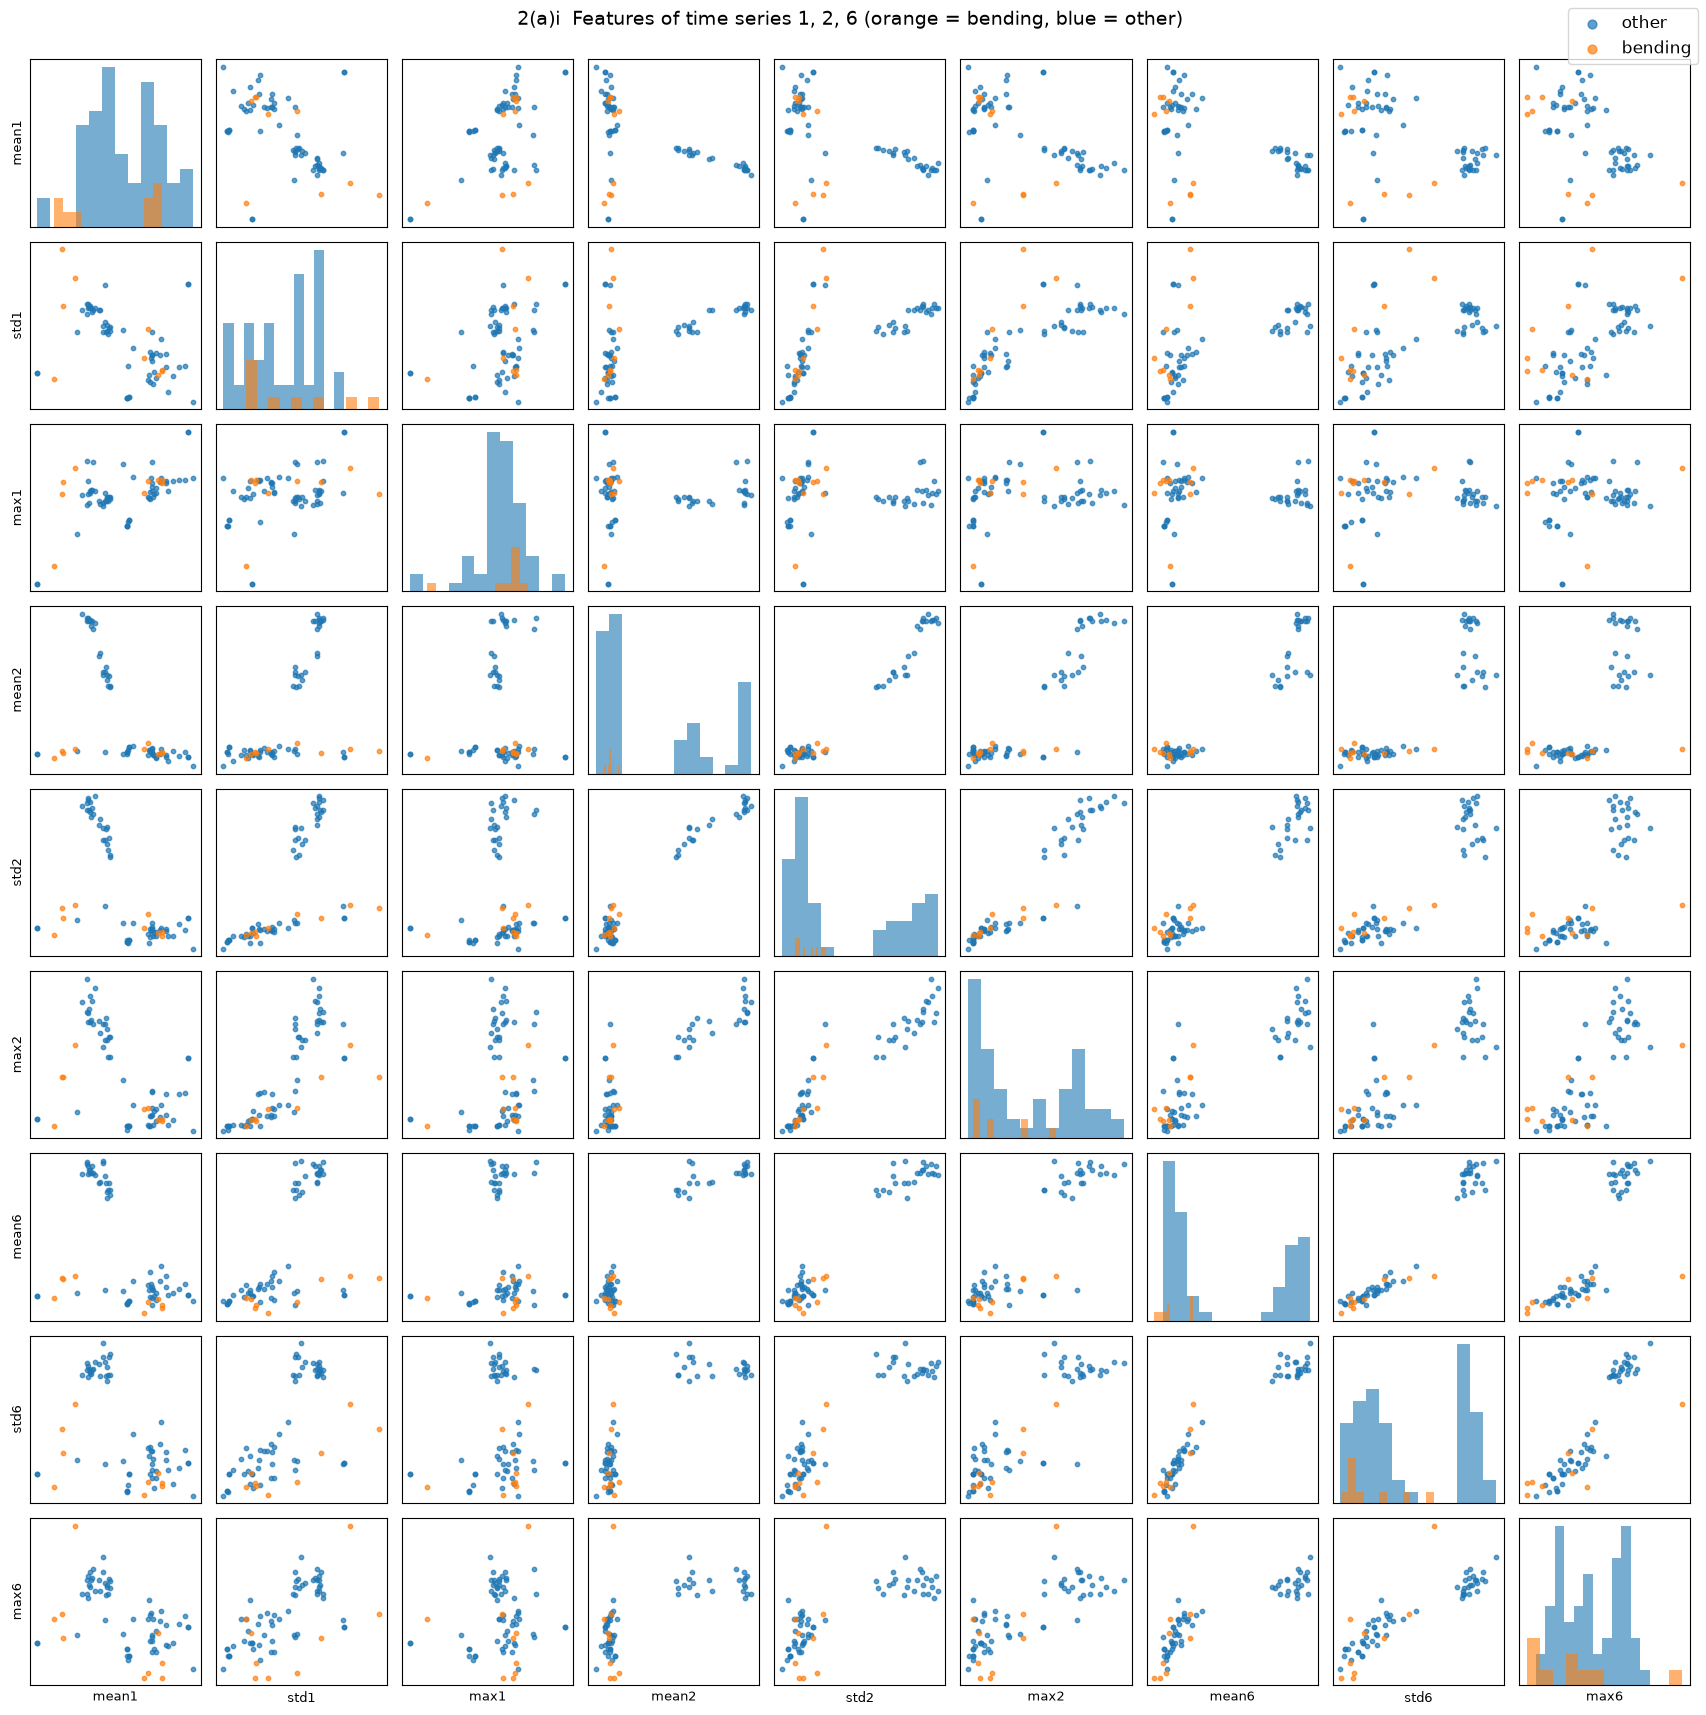

In [6]:
# Question 2ai: mean, std, max of time series 1, 2 and 6 (training set, l = 1)
Xtr1, ytr1 = get_xy(1, "train")
cols_ai = [f"{s}{i}" for i in (1, 2, 6) for s in SELECTED]
print(f"Training set: {ytr1.sum()} bending, {(ytr1 == 0).sum()} other")
scatter_grid(Xtr1[cols_ai], ytr1, "2(a)i  Features of time series 1, 2, 6 (orange = bending, blue = other)")

Figure: every pair of the 9 features (mean, std, max of time series 1, 2 and 6) on the training set; the diagonal shows histograms. Orange = bending (both bending1 and bending2), blue = all other activities.

**Analysis:**
- Bending is not separated well by any single pair of features. In most plots the bending points sit inside a cloud of "other" points.
- `mean1` and `max6` help the most: several bending instances have a lower `mean1` (or lower `max6`) than almost all other instances. Even so, a few bending points still overlap with the others.

#### ii. Breaking each time series into two halves

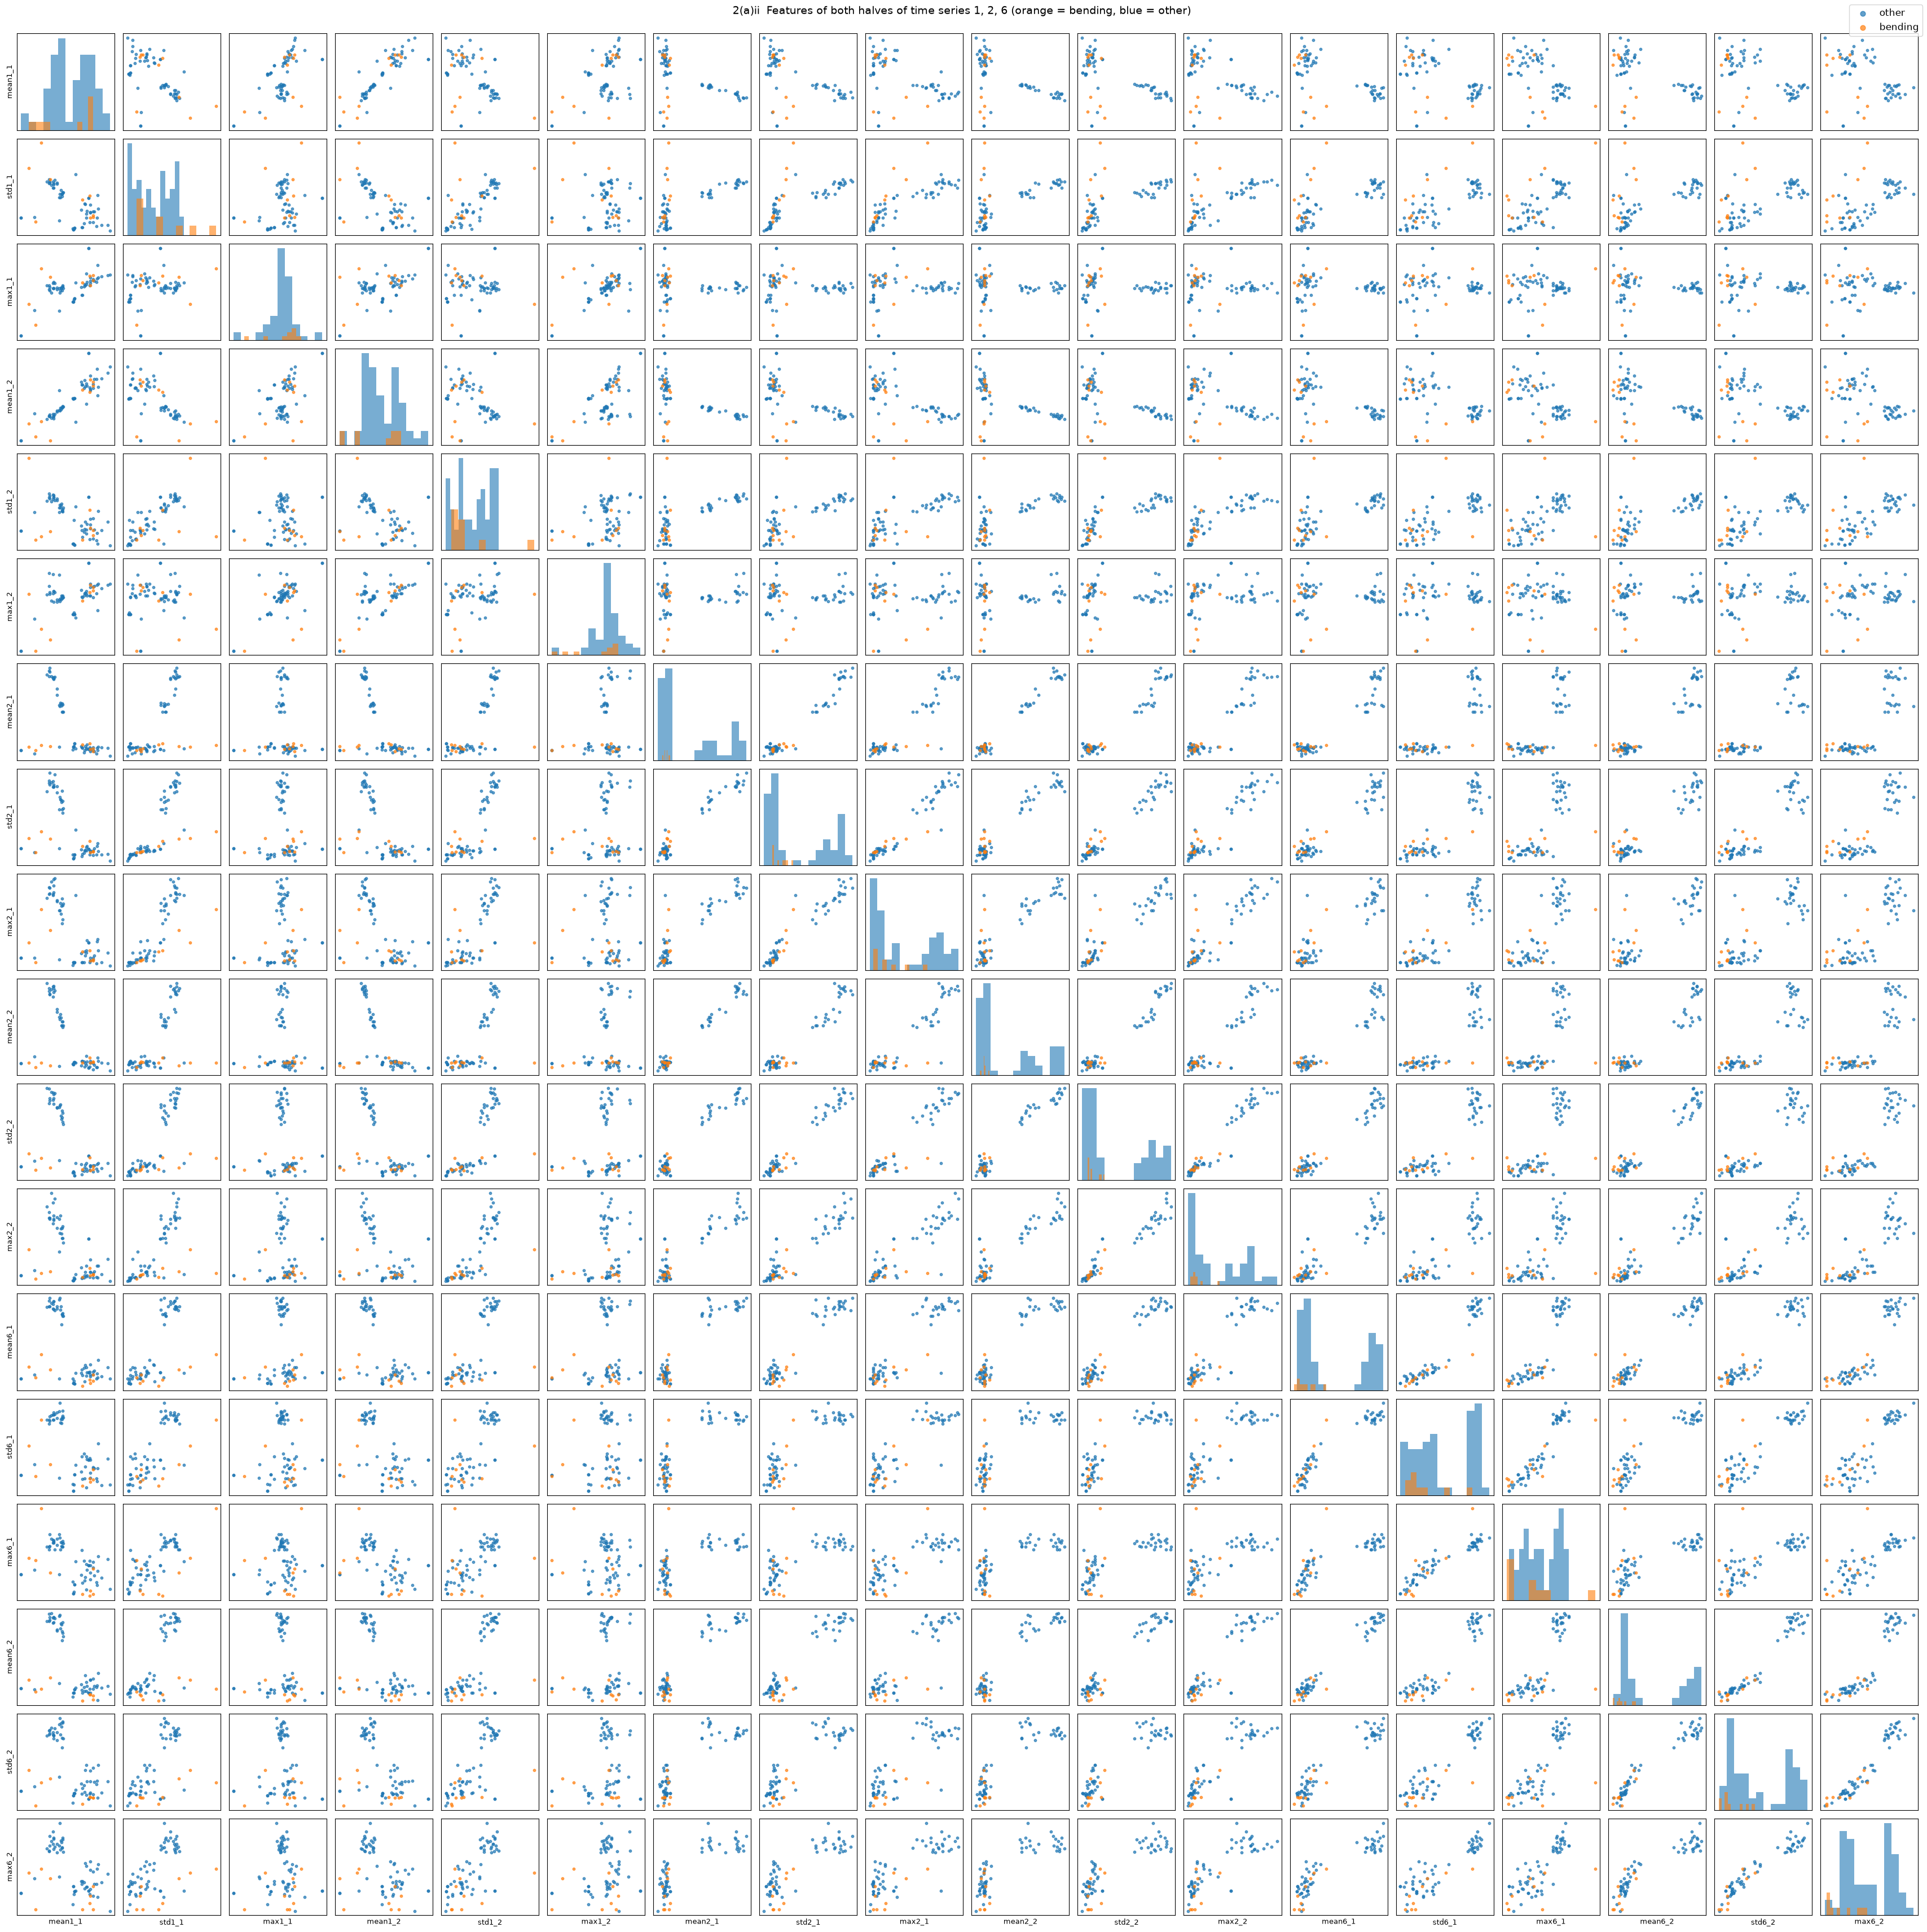

In [7]:
# Question 2aii: same features, each series broken into 2 halves (training set, l = 2)
Xtr2, ytr2 = get_xy(2, "train")
cols_aii = [f"{s}{i}_{p}" for i in (1, 2, 6) for p in (1, 2) for s in SELECTED]
scatter_grid(Xtr2[cols_aii], ytr2, "2(a)ii  Features of both halves of time series 1, 2, 6 (orange = bending, blue = other)")

**Do you see any considerable difference with 2(a)i? No.**
- Each feature from the first half is strongly correlated with the same feature from the second half because an activity looks about the same over its whole 2-minute recording.
- The patterns are the same as in 2(a)i: series 2 and 6 split low- vs. high-variance activities, bending sits with the static activities, and only `mean1` / `max6` from either half pull some bending instances away from the rest.
- So splitting into two halves doubles the number of features, but adds little new information for separating bending.

#### iii. Choosing $l \in \{1, \dots, 20\}$ and the number of features $p$ with 5-fold cross-validation

**Method** I used backward selection with Recursive Feature Elimination (RFE) on (unpenalized) logistic regression. For each $l$, every $p = 1, \dots, 18l$ is scored with 5-fold CV, and the best pair $(l, p)$ is the one with the highest CV accuracy (ties go to the smallest $p$, then the smallest $l$, i.e. the simplest model).

**The wrong way vs. the right way to cross-validate here**
- **Wrong way:** run RFE (or the p-value pruning) on the **whole training set** first, then run 5-fold CV on only the selected features to pick $p$. The selection step has already looked at the validation folds, so the features were chosen *because* they fit those instances well. The CV accuracy is then optimistically biased.
- **Right way:** treat feature selection as part of fitting the model. For each fold, standardize and run RFE using **only the 4 training folds**, then evaluate the top-$p$ features on the held-out fold. Every step that looks at labels happens inside the fold.
- Breaking the series into $l$ parts does not look at the labels (each instance is processed on its own), so it can be done before CV. Only $l$'s value is chosen by CV.

**Stratified CV.** The training set has only 9 bending instances out of 69 (13%). With plain 5-fold CV some folds could get 0 or 1 bending instances, which makes the fold accuracy meaningless (and a fold with no bending in its training part cannot even be fit). **Stratified K-fold** splits each class separately so every fold keeps about the same class proportions as the full data: here each fold has about 2 bending and 12 other instances. I use `StratifiedKFold(5, shuffle=True)`, and the same folds are reused for every model in this homework.

In [8]:
# Logistic regression helpers

def plain_lr(max_iter=100, tol=1e-4):
    """Unpenalized logistic regression: C = inf removes the default L2 penalty (footnote 3).
    max_iter stops it early when the classes are separable (footnote 5)."""
    return LogisticRegression(C=np.inf, max_iter=max_iter, tol=tol)

def l1_lr(C, solver="liblinear", max_iter=5000, tol=1e-4):
    """L1-penalized logistic regression (l1_ratio = 1); C = 1 / lambda is the budget."""
    return LogisticRegression(C=C, l1_ratio=1, solver=solver, max_iter=max_iter, tol=tol)

# Stratified 5-fold CV: every fold keeps the bending / other ratio, so no fold is missing the rare class
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=552)

In [9]:
# Question 2aiii: 5-fold CV over the pair (l, p), with RFE done INSIDE every fold (the right way)

def rfe_cv(X, y, cv):
    X = np.asarray(X)
    n_feat = X.shape[1]
    acc = np.zeros((cv.get_n_splits(), n_feat))
    for f, (tr, va) in enumerate(cv.split(X, y)):
        scaler = StandardScaler().fit(X[tr])
        Xtr, Xva = scaler.transform(X[tr]), scaler.transform(X[va])
        # n_features_to_select=1 eliminates all the way down, so ranking_ gives the full elimination
        # order: the features with ranking_ <= p are exactly the subset RFE would keep for p
        order = np.argsort(RFE(plain_lr(), n_features_to_select=1).fit(Xtr, y[tr]).ranking_)
        for p in range(1, n_feat + 1):
            cols = order[:p]
            m = plain_lr().fit(Xtr[:, cols], y[tr])
            acc[f, p - 1] = accuracy_score(y[va], m.predict(Xva[:, cols]))
    return acc.mean(axis=0)

rfe_rows = []
with threadpool_limits(limits=1):
    for l in L_VALUES:
        X, y = get_xy(l, "train")
        acc = rfe_cv(X, y, skf)
        for p, a in enumerate(acc, start=1):
            rfe_rows.append({"l": l, "p": p, "cv_accuracy": a})
rfe_results = pd.DataFrame(rfe_rows)

# Best pair: highest CV accuracy; ties broken by the fewest features p, then the smallest l
best = rfe_results.sort_values(["cv_accuracy", "p", "l"], ascending=[False, True, True]).iloc[0]
best_l, best_p, best_cv = int(best["l"]), int(best["p"]), best["cv_accuracy"]
print(f"Best (l, p) = ({best_l}, {best_p}),  5-fold CV accuracy = {best_cv:.4f}")

# Best p (and its accuracy) for every l
(rfe_results.sort_values(["cv_accuracy", "p"], ascending=[False, True])
            .groupby("l").head(1).set_index("l").sort_index()
            .rename(columns={"p": "best p"}).T.round(3))

Best (l, p) = (19, 6),  5-fold CV accuracy = 0.9857


l,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
best p,1.000,6.000,1.000,1.000,1.000,4.000,6.000,16.000,11.000,8.000,1.000,2.000,1.000,9.000,1.000,1.000,11.000,3.000,6.000,15.000
cv_accuracy,0.943,0.929,0.971,0.943,0.957,0.957,0.957,0.986,0.943,0.971,0.957,0.971,0.957,0.957,0.957,0.957,0.971,0.957,0.986,0.971


**Result:** the best pair is **$(l, p) = (19, 6)$** with a 5-fold CV accuracy of **0.986** (one misclassified instance across all folds).

The CV accuracy is high for almost every $l$ (0.93 to 0.99), and the differences between $l$ values are only 1 or 2 instances out of 69. So the exact choice of $l$ is noisy; $(l, p) = (1, 1)$ is only 3 instances worse.

#### iv. Confusion matrix, ROC and AUC on the training data; coefficients and p-values

Selected features: ['max1_11', 'std4_14', 'mean5_3', 'max5_3', 'std5_18', 'std5_19']


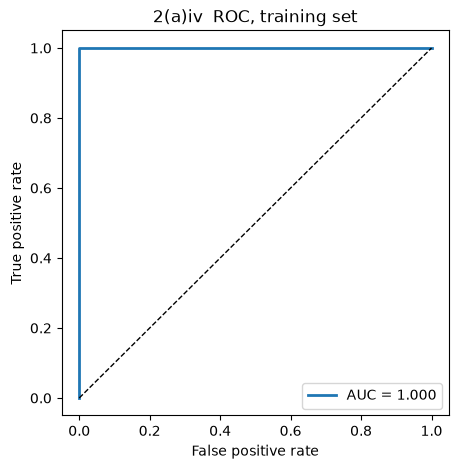

Training accuracy = 1.0000,  AUC = 1.0000


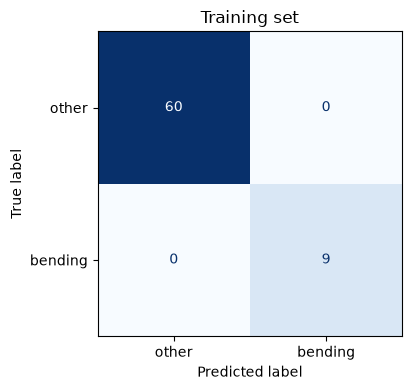

In [10]:
# Question 2aiv: refit on the whole training set with the chosen (l, p)
Xtr, ytr = get_xy(best_l, "train")
Xte, yte = get_xy(best_l, "test")

scaler = StandardScaler().fit(Xtr)
Ztr, Zte = scaler.transform(Xtr), scaler.transform(Xte)
rfe = RFE(plain_lr(), n_features_to_select=best_p).fit(Ztr, ytr)
sel = Xtr.columns[rfe.support_]
lr_final = plain_lr().fit(Ztr[:, rfe.support_], ytr)
print("Selected features:", list(sel))

def report_binary(model, Z, y, title, ax):
    # Confusion matrix + ROC/AUC for a binary model (1 = bending)
    prob = model.predict_proba(Z)[:, 1]
    pred = (prob >= 0.5).astype(int)
    cm = pd.DataFrame(confusion_matrix(y, pred, labels=[0, 1]),
                      index=["true other", "true bending"], columns=["pred other", "pred bending"])
    fpr, tpr, _ = roc_curve(y, prob)
    a = roc_auc_score(y, prob)
    ax.plot(fpr, tpr, lw=2, label=f"AUC = {a:.3f}")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.set_title(title)
    ax.legend(loc="lower right")
    return cm, accuracy_score(y, pred), a

def plot_cms(cms):
    """Plot one or more binary confusion matrices (from report_binary) as heatmaps, side by side."""
    fig, axes = plt.subplots(1, len(cms), figsize=(4.5 * len(cms), 4), squeeze=False)
    for ax, (title, cm) in zip(axes[0], cms.items()):
        ConfusionMatrixDisplay(cm.to_numpy(), display_labels=["other", "bending"]).plot(
            ax=ax, cmap="Blues", colorbar=False)
        ax.set_title(title)
    plt.tight_layout()
    plt.show()

fig, ax = plt.subplots(figsize=(5, 5))
cm_tr, acc_tr, auc_tr = report_binary(lr_final, Ztr[:, rfe.support_], ytr, "2(a)iv  ROC, training set", ax)
plt.show()
print(f"Training accuracy = {acc_tr:.4f},  AUC = {auc_tr:.4f}")
plot_cms({"Training set": cm_tr})

In [11]:
# Coefficients and p-values with statsmodels, at the scikit-learn model's betas
# statsmodels' Logit computes the Wald-test standard errors, z-statistics and p-values (like R's glm).
# start_params = the scikit-learn coefficients and maxiter=0: statsmodels does not refit the model, it only
# computes the standard errors at those betas, so the betas and p-values belong to the same model.
Zsel = sm.add_constant(pd.DataFrame(Ztr[:, rfe.support_], columns=sel))
beta_sklearn = np.r_[lr_final.intercept_, lr_final.coef_.ravel()]
with warnings.catch_warnings():
    warnings.simplefilter("ignore")      # "failed to converge" is expected: 0 iterations on purpose
    sm_fit = sm.Logit(ytr, Zsel).fit(start_params=beta_sklearn, method="newton", maxiter=0, disp=0)

assert np.allclose(sm_fit.params, beta_sklearn)    # same betas as the scikit-learn model
sm_fit.summary2().tables[1].rename(index={"const": "(intercept)"}).round(4)

,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
(intercept),-9.0495,15.5515,-0.5819,0.5606,-39.5299,21.4309
max1_11,-2.6859,11.7020,-0.2295,0.8185,-25.6214,20.2497
std4_14,-2.3925,17.2290,-0.1389,0.8896,-36.1607,31.3757
mean5_3,4.8712,58.5031,0.0833,0.9336,-109.7927,119.5351
max5_3,2.3496,70.5715,0.0333,0.9734,-135.9679,140.6672
std5_18,-2.4274,12.4094,-0.1956,0.8449,-26.7493,21.8946
std5_19,2.0314,13.2369,0.1535,0.8780,-23.9124,27.9753


The final model is refit on the **whole training set** with $l = 19$: standardize, run RFE down to $p = 6$ features, then fit the logistic regression. It classifies every training instance correctly (accuracy = 1, AUC = 1).

**Coefficients and p-values:** the $\beta$'s are the scikit-learn model's (the model used for the ROC curve and the test set). The p-values come from statsmodels' Logit: it is given those $\beta$'s as its starting point and run for 0 iterations, so it does not refit the model and only computes the Wald test at those $\beta$'s, $z_j = \hat\beta_j / \mathrm{SE}(\hat\beta_j)$ with $\mathrm{SE}$ from $(X^T W X)^{-1}$.

None of the p-values are significant (all > 0.5). Because the training classes are perfectly separated, the coefficient estimates are unstable and their standard errors are huge, so the p-values are not reliable here.

#### v. Testing on the test set

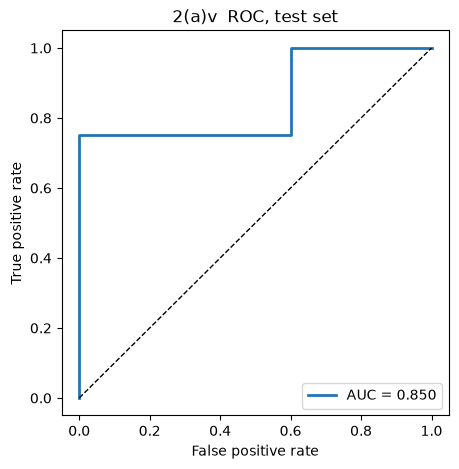

Test accuracy = 0.9474  (test error = 0.0526),  AUC = 0.8500
5-fold CV accuracy = 0.9857


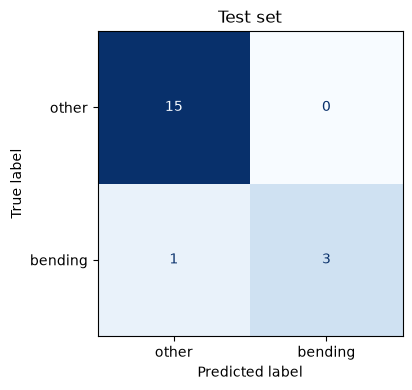

In [12]:
# Question 2av: test set, broken into the same l parts; features extracted from the test set itself
fig, ax = plt.subplots(figsize=(5, 5))
cm_te, acc_te, auc_te = report_binary(lr_final, Zte[:, rfe.support_], yte, "2(a)v  ROC, test set", ax)
plt.show()
print(f"Test accuracy = {acc_te:.4f}  (test error = {1 - acc_te:.4f}),  AUC = {auc_te:.4f}")
print(f"5-fold CV accuracy = {best_cv:.4f}")
plot_cms({"Test set": cm_te})

Each test series is broken into the same $l = 19$ parts, the features are extracted from the test instances themselves, and they are standardized with the training mean and standard deviation.

- **Test accuracy = 0.947**; test AUC = 0.85.
- **CV accuracy = 0.986**; The test accuracy is a bit lower than the CV accuracy, which is expected: $(l, p)$ was chosen because it had the highest CV accuracy, so the best CV score is slightly optimistic. With only 19 test instances, the difference is just one instance, so the two are consistent.

#### vi. Are the classes well separated (causing instability)?

In [13]:
# Question 2avi: how separated are the classes?
# Refit the unpenalized model with a tiny tolerance and more and more iterations. If the classes are
# separable, the MLE does not exist: the log-likelihood keeps improving as the coefficients grow.
rows = []
for it in [5, 10, 20, 50, 100, 1000]:
    m = plain_lr(max_iter=it, tol=1e-12).fit(Ztr[:, rfe.support_], ytr)
    prob = m.predict_proba(Ztr[:, rfe.support_])[:, 1]
    rows.append({"max_iter": it, "train accuracy": accuracy_score(ytr, (prob >= 0.5).astype(int)),
                 "largest |beta|": np.abs(m.coef_).max(), "intercept": m.intercept_[0],
                 "training log-loss": log_loss(ytr, prob)})
pd.DataFrame(rows).set_index("max_iter").round(4)

,train accuracy,largest |beta|,intercept,training log-loss
max_iter,,,,
5,1.0,1.8014,-3.7538,0.0172
10,1.0,3.9847,-7.5296,0.0005
20,1.0,9.1951,-15.6986,0.0000
50,1.0,19.1936,-31.5488,0.0000
100,1.0,19.1936,-31.5488,0.0000
1000,1.0,19.1936,-31.5488,0.0000


**Yes.** The classes are linearly separable in the selected features:
- The training accuracy is 100% and the training log-loss is essentially 0.
- When the solver runs longer, the coefficients keep growing. They only stop because the predicted probabilities reach 0 and 1 to machine precision. For separable data the MLE does not exist: making all the $\beta$'s larger always increases the likelihood, so there is no finite answer to converge to.

So the logistic regression parameters are unstable.

#### vii. Class imbalance and case-control sampling

Training-set class counts:
other      60
bending     9

pi = 0.130, pi_tilde = 0.500
intercept before adjustment = -7.860, after = -9.757
slopes: {'max1_11': np.float64(-3.023), 'std4_14': np.float64(-3.456), 'mean5_3': np.float64(4.66), 'max5_3': np.float64(2.299), 'std5_18': np.float64(-3.221), 'std5_19': np.float64(1.444)}


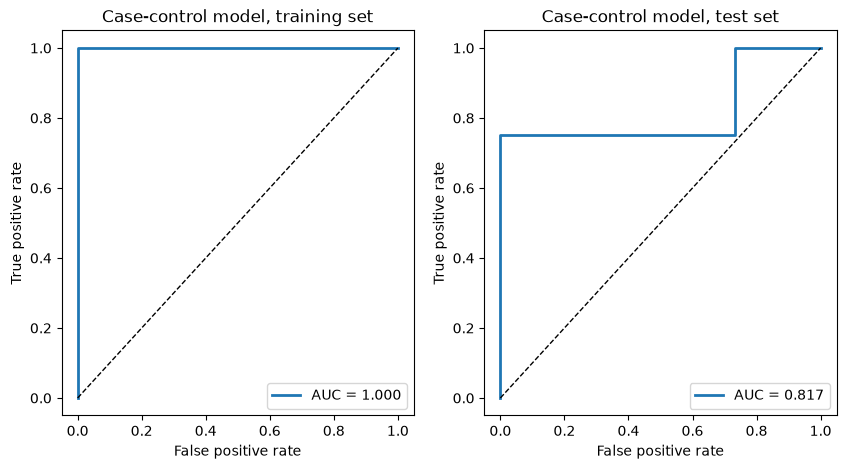

Training: accuracy = 1.0000, AUC = 1.0000
Test:     accuracy = 0.9474, AUC = 0.8167


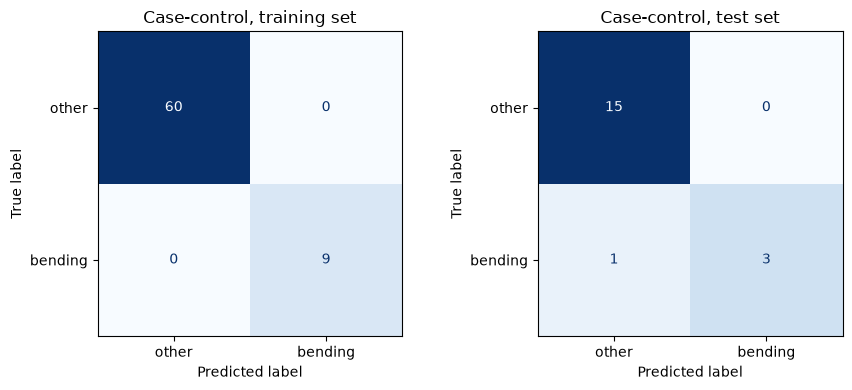

In [14]:
# Question 2avii: case-control sampling
counts = pd.Series(ytr).map({0: "other", 1: "bending"}).value_counts()
print("Training-set class counts:\n", counts.to_string(), sep="")

rng = np.random.default_rng(552)
cases = np.where(ytr == 1)[0]                                       # all bending instances
controls = rng.choice(np.where(ytr == 0)[0], size=len(cases), replace=False)   # same number of "other"
cc_idx = np.concatenate([cases, controls])

lr_cc = plain_lr().fit(Ztr[cc_idx][:, rfe.support_], ytr[cc_idx])

# Adjust the intercept for the sampling:  beta0* = beta0_hat + log(pi / (1 - pi)) - log(pi_tilde / (1 - pi_tilde))
pi = ytr.mean()                
pi_tilde = ytr[cc_idx].mean()    
b0_raw = lr_cc.intercept_[0]
lr_cc.intercept_ = lr_cc.intercept_ + np.log(pi / (1 - pi)) - np.log(pi_tilde / (1 - pi_tilde))
print(f"\npi = {pi:.3f}, pi_tilde = {pi_tilde:.3f}")
print(f"intercept before adjustment = {b0_raw:.3f}, after = {lr_cc.intercept_[0]:.3f}")
print("slopes:", dict(zip(sel, lr_cc.coef_.ravel().round(3))))

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
cm_cc_tr, acc_cc_tr, auc_cc_tr = report_binary(lr_cc, Ztr[:, rfe.support_], ytr, "Case-control model, training set", axes[0])
cm_cc_te, acc_cc_te, auc_cc_te = report_binary(lr_cc, Zte[:, rfe.support_], yte, "Case-control model, test set", axes[1])
plt.show()
print(f"Training: accuracy = {acc_cc_tr:.4f}, AUC = {auc_cc_tr:.4f}")
print(f"Test:     accuracy = {acc_cc_te:.4f}, AUC = {auc_cc_te:.4f}")
plot_cms({"Case-control, training set": cm_cc_tr, "Case-control, test set": cm_cc_te})

**Are the classes imbalanced? Yes.** The training set has 9 bending and 60 other instances (13% vs. 87%), and the test set has 4 vs. 15. The confusion matrices show the effect: the one test error is a bending instance predicted as "other" (the rare class is the one that gets missed).

**Case-control sampling:** keep all the cases (9 bending) and sample the same number of controls (9 of the 60 "other" instances, at random). Fitting on this balanced sample estimates the slopes correctly, but the intercept is shifted because the sample has 50% bending instead of the true 13%.

**Results:** the adjusted model is still perfect on the training set (accuracy = 1, AUC = 1). On the test set it has the same confusion matrix as before (accuracy = 0.947) and a test AUC of 0.817 (lower than before). With only 9 cases, case-control sampling throws away most of the controls (51 of 60), so it does not improve the model here.

### (b) Binary Classification Using $L_1$-penalized Logistic Regression

#### i. Cross-validating both $l$ and $\lambda$ (or $C = 1/\lambda$)

In [15]:
# Question 2bi: L1-penalized logistic regression, CV over l and C (= 1 / lambda)
C_GRID = np.logspace(-2, 3, 21)

l1_rows = []
for l in L_VALUES:
    X, y = get_xy(l, "train")
    gs = GridSearchCV(make_pipeline(StandardScaler(), l1_lr(1.0)),    # scaler is refit inside every fold
                      {"logisticregression__C": C_GRID}, cv=skf, scoring="accuracy", n_jobs=-1).fit(X, y)
    # among the C values tied for the best accuracy, take the smallest C (strongest penalty, sparsest model)
    res = pd.DataFrame(gs.cv_results_)
    top = res[res["mean_test_score"] == res["mean_test_score"].max()]
    C_best = top["param_logisticregression__C"].astype(float).min()
    l1_rows.append({"l": l, "best C": C_best, "cv_accuracy": top["mean_test_score"].iloc[0]})
l1_results = pd.DataFrame(l1_rows).set_index("l")

# best l: highest CV accuracy, ties -> smallest l
l1_best_l = l1_results["cv_accuracy"].idxmax()
l1_best_C = l1_results.loc[l1_best_l, "best C"]
l1_best_cv = l1_results.loc[l1_best_l, "cv_accuracy"]
print(f"Best l = {l1_best_l}, C = {l1_best_C:.4g} (lambda = {1 / l1_best_C:.4g}),  5-fold CV accuracy = {l1_best_cv:.4f}")
l1_results.T.round(3)

Best l = 12, C = 0.5623 (lambda = 1.778),  5-fold CV accuracy = 0.9857


l,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
best C,0.178,0.178,0.316,1.000,0.316,562.341,1.778,1.000,0.178,31.623,1.000,0.562,0.562,0.562,0.316,0.562,0.562,5.623,1.778,17.783
cv_accuracy,0.971,0.957,0.971,0.957,0.929,0.957,0.943,0.942,0.913,0.943,0.971,0.986,0.956,0.957,0.943,0.957,0.943,0.986,0.986,0.986


Nonzero coefficients: 5 of 216
max1_7     -0.521
std3_3      0.014
mean5_2     1.854
mean5_11    0.191
max6_11    -0.490


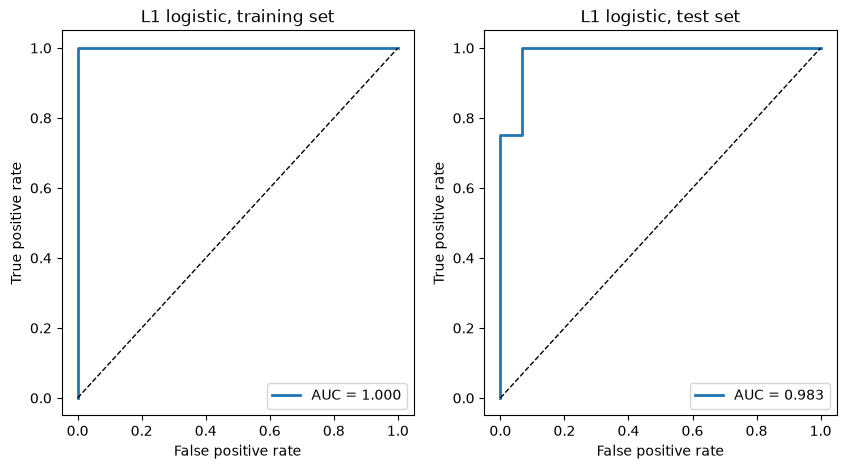

Training: accuracy = 1.0000, AUC = 1.0000
Test:     accuracy = 0.9474, AUC = 0.9833


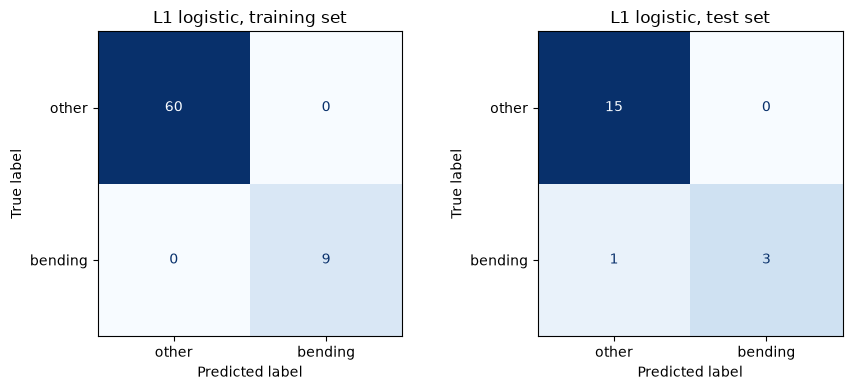

In [16]:
# Refit with the chosen (l, C) on the whole training set and test it
Xtr_b, ytr_b = get_xy(l1_best_l, "train")
Xte_b, yte_b = get_xy(l1_best_l, "test")
l1_model = make_pipeline(StandardScaler(), l1_lr(l1_best_C)).fit(Xtr_b, ytr_b)
coef = pd.Series(l1_model[-1].coef_.ravel(), index=Xtr_b.columns)
print(f"Nonzero coefficients: {(coef != 0).sum()} of {len(coef)}")
print(coef[coef != 0].round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
Ztr_b = l1_model[:-1].transform(Xtr_b); Zte_b = l1_model[:-1].transform(Xte_b)
cm_l1_tr, acc_l1_tr, auc_l1_tr = report_binary(l1_model[-1], Ztr_b, ytr_b, "L1 logistic, training set", axes[0])
cm_l1_te, acc_l1_te, auc_l1_te = report_binary(l1_model[-1], Zte_b, yte_b, "L1 logistic, test set", axes[1])
plt.show()
print(f"Training: accuracy = {acc_l1_tr:.4f}, AUC = {auc_l1_tr:.4f}")
print(f"Test:     accuracy = {acc_l1_te:.4f}, AUC = {auc_l1_te:.4f}")
plot_cms({"L1 logistic, training set": cm_l1_tr, "L1 logistic, test set": cm_l1_te})

**Result:** the best pair is **$l = 12$, $C = 0.562$** ($\lambda \approx 1.78$), with a 5-fold CV accuracy of **0.986**. The $L_1$ penalty sets all but **5 of the 216** coefficients to exactly 0, so it does variable selection automatically.

On the test set: **accuracy = 0.947** and **AUC = 0.983**.

#### ii. $L_1$-penalized vs. variable selection (RFE / p-values)

In [17]:
# Question 2bii: side-by-side comparison
pd.DataFrame({
    "RFE / p-value selection (2a)": {"l": best_l, "features used": best_p, "CV accuracy": best_cv,
                                      "test accuracy": acc_te, "test AUC": auc_te},
    "L1-penalized (2b)":            {"l": l1_best_l, "features used": int((coef != 0).sum()),
                                      "CV accuracy": l1_best_cv, "test accuracy": acc_l1_te, "test AUC": auc_l1_te},
}).round(3)

,RFE / p-value selection (2a),L1-penalized (2b)
l,19.000,12.000
features used,6.000,5.000
CV accuracy,0.986,0.986
test accuracy,0.947,0.947
test AUC,0.850,0.983


**Which performs better?** They are about the same in accuracy: both have a CV accuracy of 0.986 and a test accuracy of 0.947. The $L_1$ model is slightly better overall: it uses fewer features (5 vs 6), its test AUC is higher (0.983 vs 0.850, so its predicted probabilities rank the test instances better), and its coefficients are stable because the penalty keeps them from growing without limit on separable data.

**Which one is easier to implement? $L_1$-penalized logistic regression.** It selects variables and fits the model in one step, GridSearchCV handles the inner CV over $C$, and doing CV the right way only needs a pipeline. Variable selection with p-values or RFE needs a custom loop (RFE inside every fold, a refit for every p) and the p-values are meaningless when the classes are separable.

### (c) Multi-class Classification (The Realistic Case)

#### i. $L_1$-penalized multinomial regression

In [18]:
# Multiclass helpers: confusion matrix and one-vs-rest ROC curves
CLASSES = sorted(split.index.drop("Total"))

def report_multiclass(model, X, y, title):
    pred = model.predict(X)
    prob = model.predict_proba(X)
    classes = list(model.classes_)
    Y = label_binarize(y, classes=classes)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
    ConfusionMatrixDisplay(confusion_matrix(y, pred, labels=classes), display_labels=classes).plot(
        ax=axes[0], cmap="Blues", colorbar=False, xticks_rotation=45)
    axes[0].set_title(f"{title}: confusion matrix")

    ax = axes[1]
    aucs = {}
    for k, c in enumerate(classes):                         # one-vs-rest ROC for every class
        fpr, tpr, _ = roc_curve(Y[:, k], prob[:, k])
        aucs[c] = auc(fpr, tpr)
        ax.plot(fpr, tpr, lw=1, alpha=0.8, label=f"{c} (AUC = {aucs[c]:.2f})")
    fpr, tpr, _ = roc_curve(Y.ravel(), prob.ravel())       # micro-average: pool every (instance, class) pair
    aucs["micro-average"] = auc(fpr, tpr)
    aucs["macro-average"] = np.mean([aucs[c] for c in classes])
    ax.plot(fpr, tpr, "k", lw=2.5, label=f"micro-average (AUC = {aucs['micro-average']:.2f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.set_title(f"{title}: one-vs-rest ROC (macro AUC = {aucs['macro-average']:.2f})")
    ax.legend(loc="lower right", fontsize=8)
    plt.tight_layout()
    plt.show()
    acc = accuracy_score(y, pred)
    print(f"{title}: accuracy = {acc:.4f}, error = {1 - acc:.4f}")
    return acc, aucs

In [19]:
# Question 2ci: L1-penalized multinomial logistic regression, CV over l and C
C_GRID_MULTI = np.logspace(-1, 3, 9)

multi_rows = []
for l in L_VALUES:
    X, y = get_xy(l, "train", binary=False)
    gs = GridSearchCV(make_pipeline(StandardScaler(),    l1_lr(1.0, solver="saga", tol=1e-3).set_params(random_state=552)),
                      {"logisticregression__C": C_GRID_MULTI}, cv=skf, scoring="accuracy", n_jobs=1).fit(X, y)
    res = pd.DataFrame(gs.cv_results_)
    top = res[res["mean_test_score"] == res["mean_test_score"].max()]
    multi_rows.append({"l": l, "best C": top["param_logisticregression__C"].astype(float).min(),
                       "cv_accuracy": top["mean_test_score"].iloc[0]})
multi_results = pd.DataFrame(multi_rows).set_index("l")

m_best_l = multi_results["cv_accuracy"].idxmax()
m_best_C = multi_results.loc[m_best_l, "best C"]
print(f"Best l = {m_best_l}, C = {m_best_C:.4g},  5-fold CV accuracy = {multi_results.loc[m_best_l, 'cv_accuracy']:.4f}")
multi_results.T.round(3)

Best l = 3, C = 31.62,  5-fold CV accuracy = 0.9132


l,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
best C,1.000,100.0,31.623,100.0,31.623,100.000,10.000,1000.000,31.623,100.00,0.316,100.000,31.623,100.000,31.623,100.000,1.000,316.228,10.000,100.000
cv_accuracy,0.899,0.9,0.913,0.9,0.899,0.899,0.841,0.826,0.842,0.84,0.798,0.841,0.782,0.869,0.841,0.826,0.826,0.855,0.842,0.826


Features with a nonzero coefficient for at least one class: 54 of 54



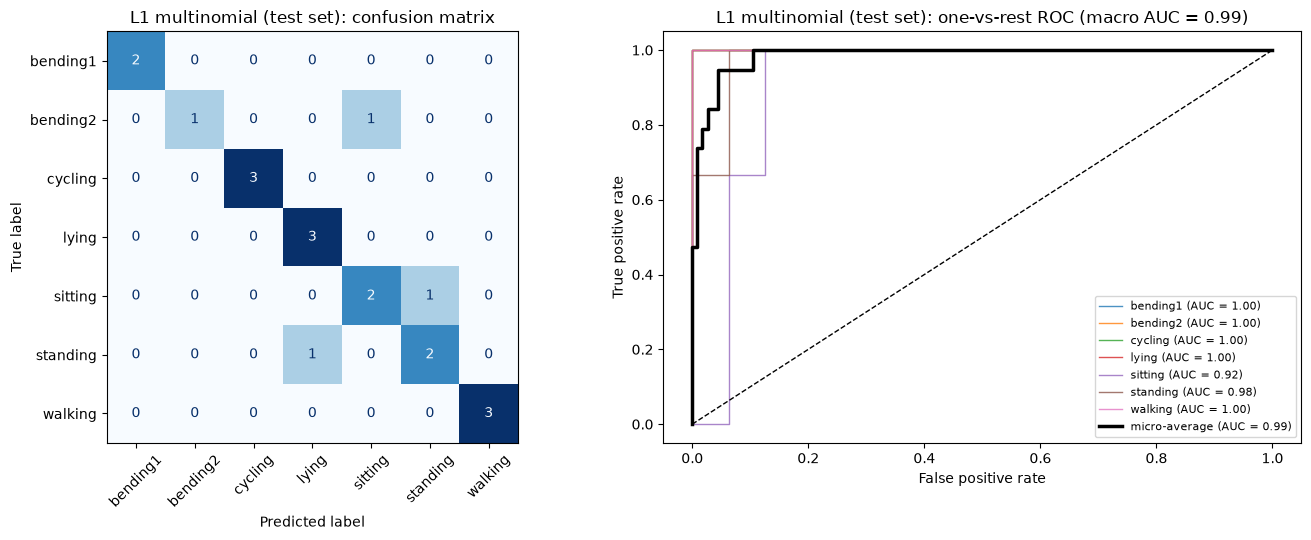

L1 multinomial (test set): accuracy = 0.8421, error = 0.1579


In [20]:
# Refit on the whole training set and test
Xtr_m, ytr_m = get_xy(m_best_l, "train", binary=False)
Xte_m, yte_m = get_xy(m_best_l, "test", binary=False)
multi_model = make_pipeline(StandardScaler(),    l1_lr(m_best_C, solver="saga", tol=1e-3).set_params(random_state=552)).fit(Xtr_m, ytr_m)
nz = (multi_model[-1].coef_ != 0).any(axis=0).sum()
print(f"Features with a nonzero coefficient for at least one class: {nz} of {Xtr_m.shape[1]}\n")
acc_multi, aucs_multi = report_multiclass(multi_model, Xte_m, yte_m, "L1 multinomial (test set)")

**Result:** the best pair is **$l = 3$, $C = 31.6$** with a 5-fold CV accuracy of 0.913.

**Test error = 0.158** (accuracy = 0.842, 16 of 19 correct). The mistakes are between similar activities: one bending2 instance is predicted as sitting, one sitting as standing, and one standing as lying. Cycling, walking, lying and bending1 are all classified correctly.

**Confusion matrices for multiclass problems:** a $K \times K$ table where entry $(i, j)$ counts the instances of true class $i$ predicted as class $j$. The diagonal holds the correct predictions and off-diagonal cells show which classes get confused with each other.

**ROC curves for multiclass problems:** ROC is defined for two classes, so it is extended with the **one-vs-rest** approach: for each class $k$, treat "class $k$" as positive and all other classes as negative, and draw an ROC curve from the predicted probability of class $k$. That gives $K$ curves. They are summarized by the
- **macro-average AUC:** the average of the $K$ per-class AUCs (every class counts equally), and the
- **micro-average ROC/AUC:** pool all $n \times K$ (instance, class) pairs into one binary problem and draw a single curve (every instance counts equally).

Here the micro-average AUC is 0.985 and the macro-average AUC is 0.985.

#### ii. Naive Bayes classifier with Gaussian and multinomial priors

$l$ is again chosen by the same stratified 5-fold CV.
- **Gaussian NB:** each feature is modeled as normal within each class, $X_j \mid Y = k \sim N(\mu_{jk}, \sigma_{jk}^2)$, independently of the other features.
- **Multinomial NB:** the features are treated like counts: each class has a probability vector over the features, and $P(x \mid Y = k) \propto \prod_j \theta_{kj}^{x_j}$. It needs non-negative features, which ours are (means, standard deviations and maxima of non-negative signals), so the raw features are used.

In [21]:
# Question 2cii: Naive Bayes with Gaussian and multinomial likelihoods, CV over l
nb_rows = []
for l in L_VALUES:
    X, y = get_xy(l, "train", binary=False)
    nb_rows.append({"l": l,
                    "Gaussian NB": cross_val_score(GaussianNB(), X, y, cv=skf).mean(),
                    "Multinomial NB": cross_val_score(MultinomialNB(), X, y, cv=skf).mean()})
nb_results = pd.DataFrame(nb_rows).set_index("l")
nb_best_l = nb_results.idxmax()          # ties -> smallest l
print("Best l:", nb_best_l.to_dict())
nb_results.T.round(3)

Best l: {'Gaussian NB': 1, 'Multinomial NB': 4}


l,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
Gaussian NB,0.898,0.869,0.886,0.870,0.870,0.841,0.885,0.841,0.798,0.826,0.840,0.841,0.781,0.825,0.797,0.812,0.797,0.812,0.84,0.825
Multinomial NB,0.824,0.823,0.882,0.884,0.869,0.854,0.854,0.854,0.869,0.825,0.868,0.840,0.854,0.838,0.825,0.840,0.838,0.825,0.84,0.810


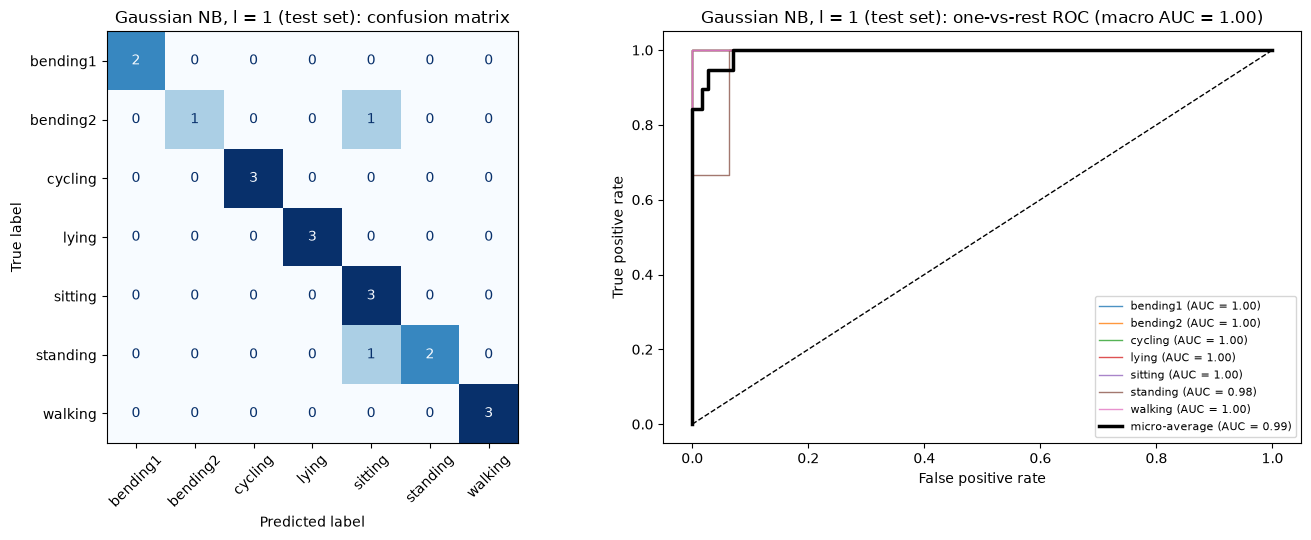

Gaussian NB, l = 1 (test set): accuracy = 0.8947, error = 0.1053


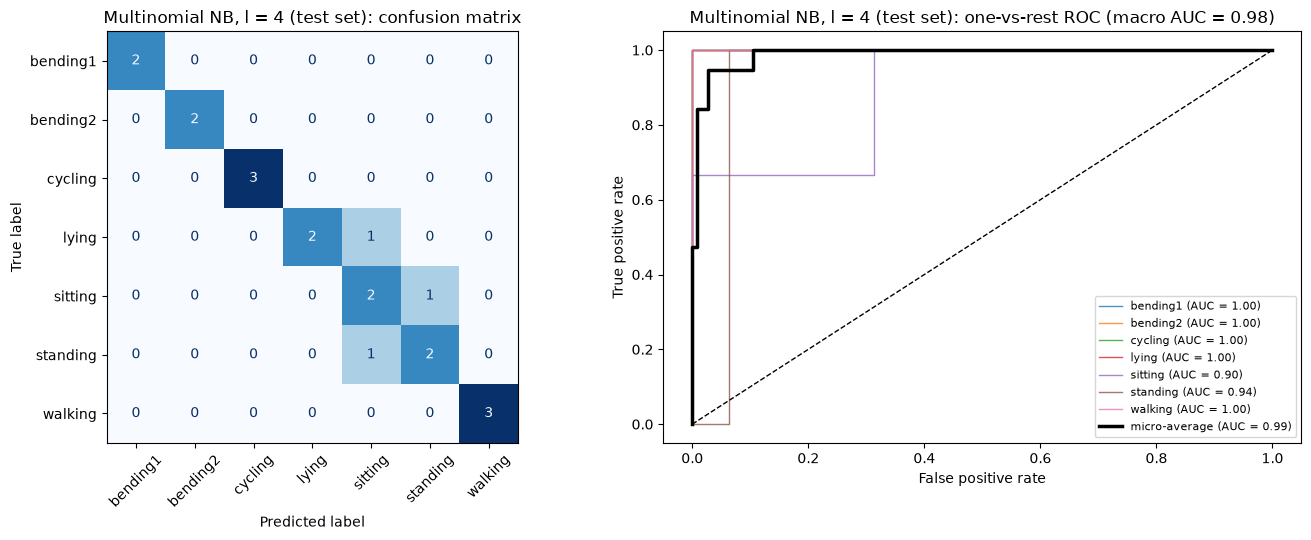

Multinomial NB, l = 4 (test set): accuracy = 0.8421, error = 0.1579


In [22]:
# Refit each Naive Bayes model with its best l and test
nb_test = {}
for name, model in [("Gaussian NB", GaussianNB()), ("Multinomial NB", MultinomialNB())]:
    l = nb_best_l[name]
    X, y = get_xy(l, "train", binary=False)
    Xt, yt = get_xy(l, "test", binary=False)
    model.fit(X, y)
    acc, aucs = report_multiclass(model, Xt, yt, f"{name}, l = {l} (test set)")
    nb_test[name] = {"l": l, "CV accuracy": nb_results.loc[l, name], "test accuracy": acc,
                     "test error": 1 - acc, "micro AUC": aucs["micro-average"], "macro AUC": aucs["macro-average"]}

**Results:**
- **Gaussian NB:** best $l = 1$ (CV accuracy 0.898). **Test error = 0.105** (17 of 19 correct), micro AUC = 0.994, macro AUC = 0.997.
- **Multinomial NB:** best $l = 4$ (CV accuracy 0.884). **Test error = 0.158** (16 of 19 correct), micro AUC = 0.988, macro AUC = 0.976.

**Comparison:** Gaussian NB is better on the test set. This makes sense for these features: they are continuous measurements (signal strength in dB and its variance), which a normal distribution per class describes reasonably well. The multinomial model is meant for counts (like word counts): it only looks at the relative proportions of the features within each instance, and it ignores their overall scale, which loses information here. Both NB models do best with small $l$: with many parts, the features become highly correlated with each other, which breaks the "independent features" assumption of Naive Bayes.

#### iii. Which method is better for multi-class classification in this problem?

In [23]:
# Question 2ciii: summary of the three multiclass classifiers
summary = pd.DataFrame({
    "L1 multinomial logistic": {"l": m_best_l, "CV accuracy": multi_results.loc[m_best_l, "cv_accuracy"],
                                "test accuracy": acc_multi, "test error": 1 - acc_multi,
                                "micro AUC": aucs_multi["micro-average"], "macro AUC": aucs_multi["macro-average"]},
    **nb_test,
})
summary.round(3)

,L1 multinomial logistic,Gaussian NB,Multinomial NB
l,3.000,1.000,4.000
CV accuracy,0.913,0.898,0.884
test accuracy,0.842,0.895,0.842
test error,0.158,0.105,0.158
micro AUC,0.985,0.994,0.988
macro AUC,0.985,0.997,0.976


All three are close, and the test set is small (19 instances, one instance = 5.3% accuracy), so the differences are only 1 instance.

- **On the test set, Gaussian Naive Bayes is the best:** lowest test error (0.105 vs. 0.158 for the other two) and the highest AUCs. It also uses the simplest features ($l = 1$, 18 features), has nothing to tune besides $l$, and fits almost instantly.
- **On cross-validation, $L_1$-penalized multinomial regression is the best** (0.913 vs. 0.898 for Gaussian NB), and its test AUCs are also very high.

Overall I would choose **Gaussian Naive Bayes** for this problem: it has the best test performance, close to the best CV performance, and it is the simplest and fastest model. With so few instances, its strong assumptions (normal, independent features) reduce variance, which helps more than the extra flexibility of the multinomial logistic regression.

## 3. ISLR 4.8.3

*This problem relates to the QDA model, in which the observations within each class are drawn from a normal distribution with a class-specific mean vector and a class-specific covariance matrix. We consider the simple case where p = 1; i.e. there is only one feature. Suppose that we have K classes, and that if an observation belongs to the kth class then X comes from a one-dimensional normal distribution, $X \sim N(\mu_k, \sigma_k^2)$. Recall that the density function for the one-dimensional normal distribution is given in (4.16). Prove that in this case, the Bayes classifier is not linear. Argue that it is in fact quadratic.*

The Bayes classifier assigns $x$ to the class with the largest posterior probability. By Bayes' theorem,

$$p_k(x) = \Pr(Y = k \mid X = x) = \frac{\pi_k f_k(x)}{\sum_{l=1}^{K} \pi_l f_l(x)}, \qquad f_k(x) = \frac{1}{\sqrt{2\pi}\,\sigma_k} \exp\left(-\frac{(x - \mu_k)^2}{2\sigma_k^2}\right).$$

The denominator is the same for every class, so the classifier picks the $k$ that maximizes $\pi_k f_k(x)$. The log is increasing, so this is the same as maximizing

$$\log\left(\pi_k f_k(x)\right) = \log \pi_k - \log\sqrt{2\pi} - \log \sigma_k - \frac{(x - \mu_k)^2}{2\sigma_k^2}.$$

$\log\sqrt{2\pi}$ is the same for every class, so we can drop it. Expanding the square $(x - \mu_k)^2 = x^2 - 2x\mu_k + \mu_k^2$ gives the discriminant function

$$\delta_k(x) = -\frac{x^2}{2\sigma_k^2} + \frac{\mu_k}{\sigma_k^2}\,x - \frac{\mu_k^2}{2\sigma_k^2} - \log \sigma_k + \log \pi_k,$$

and $x$ is assigned to the class with the largest $\delta_k(x)$.

**Why it is not linear:** In Section 4.4.1 (LDA), all classes share one variance $\sigma^2$. Then the $-\frac{x^2}{2\sigma^2}$ term (and $-\log \sigma$) is the same for every class and can be dropped, leaving $\delta_k(x) = \frac{\mu_k}{\sigma^2}x - \frac{\mu_k^2}{2\sigma^2} + \log\pi_k$, which is linear in $x$. However, with QDA, $\sigma_k$ is different for each class, so the coefficient of $x^2$, $-\frac{1}{2\sigma_k^2}$, is different for each class and **cannot** be dropped.

**Why it is quadratic:** Each $\delta_k(x) = a_k x^2 + b_k x + c_k$ with $a_k = -\frac{1}{2\sigma_k^2}$, $b_k = \frac{\mu_k}{\sigma_k^2}$, $c_k = -\frac{\mu_k^2}{2\sigma_k^2} - \log\sigma_k + \log\pi_k$. The boundary between classes $k$ and $l$ is where $\delta_k(x) = \delta_l(x)$:

$$\left(\frac{1}{2\sigma_l^2} - \frac{1}{2\sigma_k^2}\right)x^2 + \left(\frac{\mu_k}{\sigma_k^2} - \frac{\mu_l}{\sigma_l^2}\right)x + (c_k - c_l) = 0.$$

When $\sigma_k \neq \sigma_l$, the $x^2$ coefficient is nonzero, so this is a quadratic equation in $x$ (it can have two roots, so a class can own two separate intervals of the real line, which a linear rule can never produce). So the Bayes classifier is quadratic in $x$, not linear. It only reduces to the linear (LDA) case when $\sigma_k = \sigma_l$.

## 4. ISLR 4.8.7

*Suppose that we wish to predict whether a given stock will issue a dividend this year ("Yes" or "No") based on X, last year's percent profit. We examine a large number of companies and discover that the mean value of X for companies that issued a dividend was $\bar{X} = 10$, while the mean for those that didn't was $\bar{X} = 0$. In addition, the variance of X for these two sets of companies was $\hat{\sigma}^2 = 36$. Finally, 80% of companies issued dividends. Assuming that X follows a normal distribution, predict the probability that a company will issue a dividend this year given that its percentage profit was X = 4 last year.*

Given: $\pi_{\text{Yes}} = 0.8$, $\pi_{\text{No}} = 0.2$, $\mu_{\text{Yes}} = 10$, $\mu_{\text{No}} = 0$, $\sigma^2 = 36$ (shared), $x = 4$.

By Bayes' theorem,

$$\Pr(\text{Yes} \mid X = 4) = \frac{\pi_{\text{Yes}} f_{\text{Yes}}(4)}{\pi_{\text{Yes}} f_{\text{Yes}}(4) + \pi_{\text{No}} f_{\text{No}}(4)}, \qquad f_k(x) = \frac{1}{\sqrt{2\pi \cdot 36}} \exp\left(-\frac{(x - \mu_k)^2}{2 \cdot 36}\right).$$

Both classes have the same variance, so the constant $\frac{1}{\sqrt{72\pi}}$ cancels:

$$\Pr(\text{Yes} \mid X = 4) = \frac{0.8\, e^{-(4-10)^2/72}}{0.8\, e^{-(4-10)^2/72} + 0.2\, e^{-(4-0)^2/72}} = \frac{0.8\, e^{-0.5}}{0.8\, e^{-0.5} + 0.2\, e^{-0.2222}}$$

$$= \frac{0.8(0.6065)}{0.8(0.6065) + 0.2(0.8007)} = \frac{0.4852}{0.4852 + 0.1601} = \frac{0.4852}{0.6454} \approx 0.752.$$

**The probability that the company issues a dividend this year is about 75.2%.**

In [24]:
# Question 4 (ISLR 4.8.7): check the arithmetic
pi_yes, pi_no, mu_yes, mu_no, var, x = 0.8, 0.2, 10, 0, 36, 4
f = lambda x, mu: np.exp(-(x - mu) ** 2 / (2 * var)) / np.sqrt(2 * np.pi * var)
p_yes = pi_yes * f(x, mu_yes) / (pi_yes * f(x, mu_yes) + pi_no * f(x, mu_no))
print(f"P(dividend | X = 4) = {p_yes:.4f}")

P(dividend | X = 4) = 0.7519
